In [1]:
import numpy as np
import math
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import LogNorm

import matplotlib as mpl

from scipy import interpolate
import scipy.optimize

from copy import deepcopy
import time
from tqdm import tqdm

from ngsolve import *
from ngsolve.webgui import Draw
from netgen.csg import *

from netgen.occ import *
from netgen.meshing import IdentificationType

# my functions
from helper_functions import *
from dipole_poisson_solver_tmdc import dipole_poisson_solver

In [2]:
### unit-system: Angstrom = 1, eV = 1, e_charge = 1

### choices, see lammps metal system: https://docs.lammps.org/units.html

Angstrom = 1
eV = 1
e_charge = 1
Volt = 1

### independent

finestructure_constant = 0.0072973525643 # Finestructure constant, independent of unit-system   , https://en.wikipedia.org/wiki/Fine-structure_constant

### derived

hbar = 6.582119569 * pow(10.0, -4.0) ## eV * pico seconds, 1 pico second = 10^(-12) seconds

### units of time are in pico seconds, this implies units of velocity are in Angstrom / picoseconds

c_speed_of_light = 2.99792458 * pow(10.0, 6.0) ## Angstrom/pico seconds

pico_second = 1

nm = 10 ## 1nm = 10 Angstrom


hbar_times_c = 1973  # eV * Angstrom  # https://en.wikipedia.org/wiki/Planck_constant#Reduced_Planck_constant
h_times_c = 2.0 * np.pi * hbar_times_c

epsilon_0 = (e_charge * e_charge) / (2.0 * finestructure_constant * h_times_c)    # https://en.wikipedia.org/wiki/Vacuum_permittivity
mu_0 = 1.0 / (c_speed_of_light * epsilon_0)    # https://en.wikipedia.org/wiki/Vacuum_permeability
mu_0 /= c_speed_of_light ### don't divide by c^2 immediately

######################
######################
######################


### constants
a_lattice = 2.46

grapheneheight = 3.35 # Angstrom

blg_grapheneheight = grapheneheight ### see Jung & MacDonald PRB 89, 035405 (2014) #2.0 * grapheneheight
MoS2_1L_height = 12.29 # this is the perpendicular unit cell size according to the Ab initio tight binding paper

bilayer_graphene_area, bilayer_graphene_volume = blg_area_vol(a_lattice, blg_grapheneheight, Angstrom)
print(blg_grapheneheight)

3.35


In [3]:
# eps tensor
inplane_hBn_bulk = 4.98 ### see https://www.nature.com/articles/s41699-018-0050-x 
outofplane_hBn_bulk = 3.03

inplane_graphene = 1.8 ### https://pubs.acs.org/doi/10.1021/nl303611v
outofplane_graphene = 3

inplane_MoS2 = 15.4 ### https://www.nature.com/articles/s41699-018-0050-x
outofplane_MoS2 = 6.1

In [4]:
idos_tmdc = np.load('DOS_calculations/idos_MoS2_energy_deviation_05e-3.npy')
energies_tmdc = np.load('DOS_calculations/idos_MoS2_energies_energy_deviation_05e-3.npy')
energy_increment_idos = energies_tmdc[1] - energies_tmdc[0]


idos_tmdc_interpolated = scipy.interpolate.interp1d(energies_tmdc, idos_tmdc, kind='linear') # use other interpolator here
en_min_tmdc = energies_tmdc[0]
en_max_tmdc = energies_tmdc[-1]

pot_min = 0.0
pot_max = 0.2


In [5]:
vac_box_width = 250 #700 * nm
height_bottom = 15 * nm 
height_top = height_bottom
vac_box_width = height_bottom * 15 # box width is 10 times hbn thickness
dipole_moment_debye = 40

sphere_radius = 3 # 3
benzen_a = 1.4 # Angstrom
benzen_diameter = 2 * benzen_a
dipole_position = 6 # 0.02 * vac_box_width # basically 0


dipole_d = 3 * benzen_diameter 

back_gate = 0.1 #0.05 - 0.5
#max_h = vac_box_width/20 #vac_box_width/15
hbn_maxh = 0.8
blg_maxh = 0.3

cut_percentage = 0.2
larger_cut_percentage = 0.7
lam = 100000

#fem_n = 200
epsilon_z = 1e-4
epsilon_boundary = 0.0
print('simulation dimensions in Angstrom: ')
print('hBb thickness: ', height_bottom)
print('blg thichness: ', blg_grapheneheight)
print('box width: ', vac_box_width)
print('dipole d: ', dipole_d)
print('dipole height over hBn: ', dipole_position)
print('dipole sphere radius: ', sphere_radius)
print('back gate voltage: ', back_gate)
#print('maxh/fem_n: ', max_h/(vac_box_width/(fem_n - 1)))

simulation dimensions in Angstrom: 
hBb thickness:  150
blg thichness:  3.35
box width:  2250
dipole d:  8.399999999999999
dipole height over hBn:  6
dipole sphere radius:  3
back gate voltage:  0.1


In [ ]:
### grid search parameters

number_fem_ns = 3
number_max_hs = 3

min_fem_n = 100
max_fem_n = 400

# largest max_h is least precise
max_max_h = vac_box_width/10
min_max_h = vac_box_width/25

fem_ns = np.linspace(min_fem_n, max_fem_n, number_fem_ns)
max_hs = np.linspace(max_max_h, min_max_h, number_max_hs)

succs = np.zeros((number_fem_ns, number_max_hs))
min_errors_rho = np.zeros((number_fem_ns, number_max_hs))
min_errors_q = np.zeros((number_fem_ns, number_max_hs))

In [7]:
for i, fem_n in enumerate(fem_ns):
    for j in range(number_max_hs):
        max_h = max_hs[j]
        fem_n = int(fem_n)
        material = 'tmdc'
        test_solver = dipole_poisson_solver(material, dipole_moment_debye, dipole_d, dipole_position, inplane_hBn_bulk, outofplane_hBn_bulk, inplane_MoS2, outofplane_MoS2, epsilon_0)
        test_solver.build_geometry(vac_box_width, height_bottom, height_top, MoS2_1L_height, sphere_radius, max_h, hbn_maxh, blg_maxh)
        test_solver.solve_without_tmdc(back_gate)

        show_plots = False
        test_solver.solve(fem_n, epsilon_z, epsilon_boundary, idos_tmdc_interpolated, en_min_tmdc, en_max_tmdc, pot_min, pot_max, show_plots, cut_percentage, larger_cut_percentage, lam, use_abs=True, starting_alpha=0.001)

        succs[i, j] = test_solver.sol.success
        min_errors_rho[i, j] = np.min(np.array(test_solver.rho_diff))
        min_errors_q[i, j] = np.min(np.array(test_solver.q_diff))

iteration:  0
# 0   rho_n-1 - rho_n (max):  0.000577750000284089
# 0   |q_n-1 - q_n| :  6296.183925615475
iteration:  1
# 1   rho_n-1 - rho_n (max):  0.0748132370100813
# 1   |q_n-1 - q_n| :  1821443.6614440305
iteration:  2
# 2   rho_n-1 - rho_n (max):  0.1304947403532107
# 2   |q_n-1 - q_n| :  3505440.154444858
iteration:  3
# 3   rho_n-1 - rho_n (max):  0.000519975000255709
# 3   |q_n-1 - q_n| :  816.0766117165521
iteration:  4
# 4   rho_n-1 - rho_n (max):  0.00042878994161198896
# 4   |q_n-1 - q_n| :  672.9656774079009
iteration:  5
# 5   rho_n-1 - rho_n (max):  9.598334431513283e-09
# 5   |q_n-1 - q_n| :  0.00040229973478744796
iteration:  6
# 6   rho_n-1 - rho_n (max):  2.1439035442771814e-13
# 6   |q_n-1 - q_n| :  1.3940734788775444e-08
solver takes  0.36455678939819336  seconds and  7  iterations
charge = 1451.888069270816
iteration:  0
# 0   rho_n-1 - rho_n (max):  0.0005777500002840893
# 0   |q_n-1 - q_n| :  6289.942758804545
iteration:  1
# 1   rho_n-1 - rho_n (max):  0.0748

In [8]:
print(succs)

[[1. 1. 1.]
 [1. 1. 1.]
 [1. 1. 1.]]


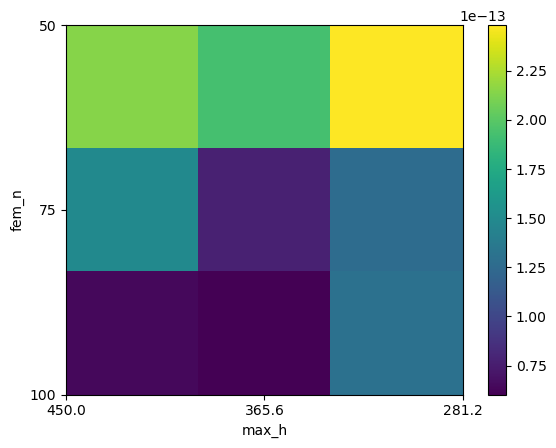

In [ ]:
plt.imshow(min_errors_rho, extent=(max_max_h, min_max_h, max_fem_n, min_fem_n), aspect='auto')
plt.xlabel('max_h')
plt.ylabel('fem_n')
plt.yticks(fem_ns)
plt.xticks(max_hs,)
plt.colorbar()

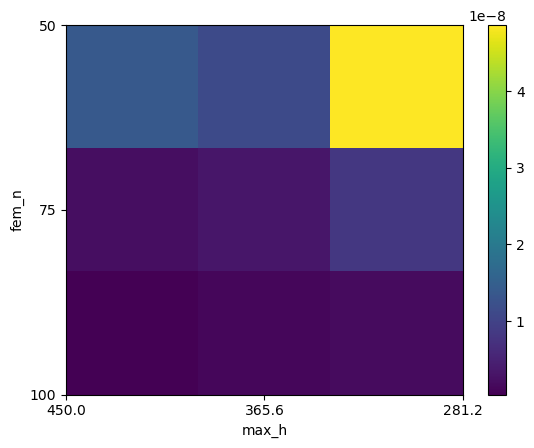

In [31]:
plt.imshow(min_errors_q, extent=(max_max_h, min_max_h, max_fem_n, min_fem_n), aspect='auto')
plt.yticks(fem_ns)
plt.xticks(max_hs)
plt.xlabel('max_h')
plt.ylabel('fem_n')
plt.colorbar()

In [ ]:
print(min_errors_rho[2, 1])
print(min_errors_rho[0, 2])

In [ ]:
for i, fem_n in enumerate(fem_ns):
    for j in range(number_max_hs):
        max_h = max_hs[j]
        fem_n = int(fem_n)
        print('i = ', i, ' j = ', j)
        print('max_h: ', max_h)
        print('fem_n: ', fem_n)